# Interactive TOM + LVIS exploration with PyVista

This test notebook renders a small real BIOMASS L2A tomogram as a volume and real LVIS RH98 footprints as vertical stems in the same local metric scene. It also derives two deliberately labelled **scattering-structure proxies**: the height centroid and the fraction of vertical power above 5 m. They are useful for exploration, but are not calibrated biomass, plant area density, or canopy cover.

Install with `python -m pip install -e '.[tomogram,lvis,examples,visualisation]'`. The interactive Jupyter backend uses Trame; change `client` to `static` below when remote rendering is unavailable.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

from tomo_canopy.processors import LVISProcessor, TomogramProcessor

pv.set_jupyter_backend("client")

## Locate overlapping real products

The selected 0.02° × 0.02° window contains a dense LVIS flight-line segment and valid TOM samples while remaining small enough for interactive volume rendering. Bounds are always `(minimum longitude, minimum latitude, maximum longitude, maximum latitude)`.

In [2]:
project_root = next(
    path for path in (Path.cwd(), Path.cwd().parent)
    if (path / "pyproject.toml").exists()
)
tom_source = next((project_root / "data" / "TOM").glob("*L2A*"))
lvis_source = (
    project_root / "data" / "lvisc" / "raw"
    / "LVISC2_Gabon2023_0520_R2507_055255.TXT"
)
bounds = (11.480, -0.080, 11.500, -0.060)
tom_source.name, lvis_source.name, bounds

('BIO_TP_TOM_L2A_20251007T050300_20251022T050313_C_G___M___C___T____F001_01_QRDMUH',
 'LVISC2_Gabon2023_0520_R2507_055255.TXT',
 (11.48, -0.08, 11.5, -0.06))

## Prepare TOM scattering power

We keep HV and relative heights from −10 to 60 m. The provider subsets before loading, so the full multi-gigabyte cube is never materialized. Decibels are convenient for display; linear power is retained for the vertical proxies.

In [3]:
tom_processor = TomogramProcessor()
tom = tom_processor.open(
    tom_source,
    expected_level="L2A",
    polarization="HV",
    height_range=(-10, 60),
    bounds=bounds,
    chunks="auto",
)
tom = tom_processor.to_power(tom)
tom = tom_processor.to_db(tom, floor_db=-35).load()
tom

<xarray.Dataset> Size: 996kB
Dimensions:               (polarization: 1, z: 36, y: 48, x: 48)
Coordinates:
  * polarization          (polarization) <U2 8B 'HV'
  * z                     (z) float64 288B -10.0 -8.0 -6.0 ... 56.0 58.0 60.0
  * y                     (y) float64 384B -0.07961 -0.07919 ... -0.06003
  * x                     (x) float64 384B 11.48 11.48 11.48 ... 11.5 11.5 11.5
Data variables:
    tomographic_cube      (polarization, z, y, x) float32 332kB 0.004514 ... ...
    tomographic_power     (polarization, z, y, x) float32 332kB 2.038e-05 ......
    tomographic_power_db  (polarization, z, y, x) float32 332kB -35.0 ... -35.0
Attributes: (12/16)
    coordinate_normalization:  XML latitude/longitude field semantics; STAC b...
    source:                    /home/simon/Documents/science/GFZ/projects/bio...
    product_root:              /home/simon/Documents/science/GFZ/projects/bio...
    product_id:                BIO_TP_TOM_L2A_20251007T050300_20251022T050313...
    product_level:             L2A
    modality:                  tomogram
    ...                        ...
    stac_bbox:                 (-0.66627765760239, 10.86641062088875, 0.69247...
    coordinate_space:          geographic
    acquisition_start:         2025-10-07T05:03:00.188646Z
    acquisition_end:           2025-10-22T05:03:13.292892Z
    processing_quantity:       power_db
    decibel_floor:             -35.0

## Ecological interpretation layer

Normalizing each vertical profile removes absolute magnitude and describes where scattering is distributed. The centroid summarizes its vertical centre of mass; the above-ground fraction separates power above 5 m from near-ground scattering. Interpret both comparatively until they have been validated against field or lidar structure.

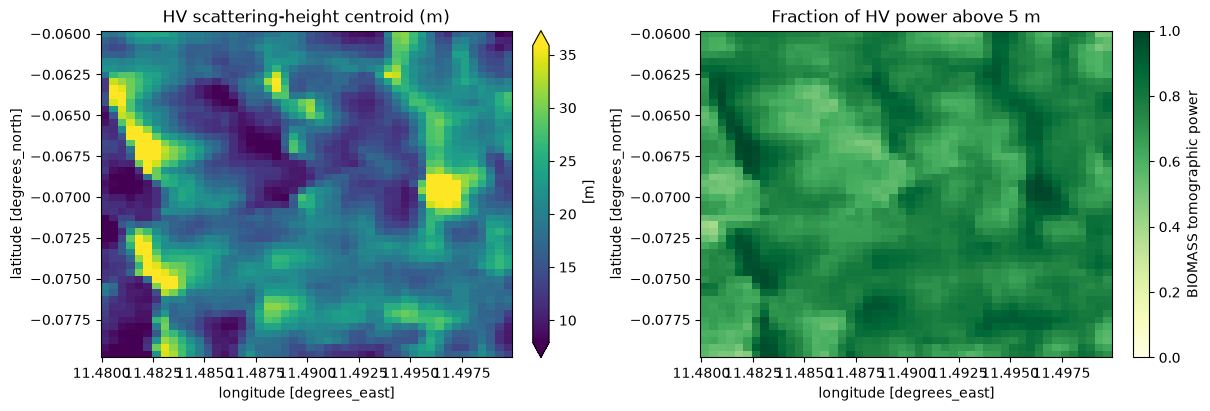

In [4]:
power = tom.tomographic_power.sel(polarization="HV")
total_power = power.sum("z", min_count=1)
profile = power / total_power.where(total_power > 0)
scattering_centroid = (profile * profile.z).sum("z", min_count=1)
above_ground_power = power.where(power.z >= 5).sum("z", min_count=1)
above_ground_fraction = above_ground_power / total_power.where(total_power > 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
scattering_centroid.plot(ax=axes[0], cmap="viridis", robust=True)
axes[0].set_title("HV scattering-height centroid (m)")
above_ground_fraction.plot(ax=axes[1], cmap="YlGn", vmin=0, vmax=1)
axes[1].set_title("Fraction of HV power above 5 m")
plt.show()

## Prepare LVIS footprints

RH98 is height above the LVIS ground return, so it shares the tomogram's relative-height convention without mixing absolute elevation into the scene. Quality filtering is explicit and the displayed footprints are reproducibly sampled.

In [5]:
lvis_processor = LVISProcessor()
lvis = lvis_processor.open(
    lvis_source,
    variables=["rh", "sensitivity"],
    bounds=bounds,
    max_shots=5000,
)
lvis = lvis_processor.filter_quality(
    lvis, minimum_sensitivity=0.9, require_finite_rh=True
)
lvis = lvis_processor.add_rh_metric(lvis, percentile=98)
lvis = lvis_processor.sample_shots(lvis, count=400, seed=42)
lvis

<xarray.Dataset> Size: 59kB
Dimensions:      (shot: 400, percentile: 23)
Coordinates:
  * shot         (shot) int64 3kB 26 34 48 94 105 ... 4953 4955 4961 4976 4991
    shot_number  (shot) int64 3kB 8390784 8390858 8390997 ... 8397640 8397655
    longitude    (shot) float64 3kB 11.5 11.5 11.5 11.5 ... 11.49 11.49 11.49
    latitude     (shot) float64 3kB -0.07966 -0.07961 ... -0.07382 -0.07265
    x            (shot) float64 3kB 11.5 11.5 11.5 11.5 ... 11.49 11.49 11.49
    y            (shot) float64 3kB -0.07966 -0.07961 ... -0.07382 -0.07265
  * percentile   (percentile) int16 46B 10 15 20 25 30 35 ... 95 96 97 98 99 100
Data variables:
    rh           (shot, percentile) float32 37kB 4.01 6.55 9.14 ... 45.14 46.86
    sensitivity  (shot) float32 2kB 0.997 0.996 0.997 ... 0.997 0.997 0.997
    rh98         (shot) float32 2kB 21.01 23.56 32.63 ... 29.76 43.76 44.62
Attributes: (12/17)
    source:               /home/simon/Documents/science/GFZ/projects/biomass-...
    product_id:           LVISC2_Gabon2023_0520_R2507_055255
    source_format:        ASCII TXT
    product_level:        L2
    sensor:               LVIS-C
    modality:             lvis
    ...                   ...
    release:              R2507
    segment:              055255
    quality_filters:      {'minimum_sensitivity': 0.9, 'require_finite_rh': T...
    source_shot_count:    5000
    retained_shot_count:  5000
    sample_seed:          42

## Build one metric 3D scene

Longitude and latitude are converted to local metres for visualization only. This avoids visually mixing angular horizontal units with metre heights. TOM opacity is driven by robustly scaled dB power. LVIS ground points sit at relative height 0 and stems end at RH98.

In [ ]:
lon0 = float(tom.x.mean())
lat0 = float(tom.y.mean())
metres_per_degree_lat = 111_132.0
metres_per_degree_lon = 111_320.0 * np.cos(np.deg2rad(lat0))
to_local_x = lambda longitude: (np.asarray(longitude) - lon0) * metres_per_degree_lon
to_local_y = lambda latitude: (np.asarray(latitude) - lat0) * metres_per_degree_lat

x_m = to_local_x(tom.x.values)
y_m = to_local_y(tom.y.values)
z_m = tom.z.values
volume_db = tom.tomographic_power_db.sel(polarization="HV").transpose("x", "y", "z").values
low, high = np.nanpercentile(volume_db, [5, 99.5])
display_power = np.clip((volume_db - low) / (high - low), 0, 1)

grid = pv.RectilinearGrid(x_m, y_m, z_m)
grid.point_data["HV power"] = display_power.ravel(order="F")

shot_x = to_local_x(lvis.longitude.values)
shot_y = to_local_y(lvis.latitude.values)
rh98 = lvis.rh98.values
tops = pv.PolyData(np.column_stack([shot_x, shot_y, rh98]))
tops["RH98 (m)"] = rh98

stem_points = np.empty((2 * len(rh98), 3), dtype=float)
stem_points[0::2] = np.column_stack([shot_x, shot_y, np.zeros_like(rh98)])
stem_points[1::2] = np.column_stack([shot_x, shot_y, rh98])
stems = pv.PolyData(stem_points)
stems.lines = np.column_stack([np.full(len(rh98), 2), 2*np.arange(len(rh98)), 2*np.arange(len(rh98))+1]).ravel()

plotter = pv.Plotter(notebook=True)
plotter.add_volume(
    grid, scalars="HV power", cmap="magma",
    opacity=[0.0, 0.0, 0.01, 0.04, 0.12, 0.35], shade=False,
)
plotter.add_mesh(stems, color="deepskyblue", opacity=0.45, line_width=1)
plotter.add_mesh(
    tops, scalars="RH98 (m)", cmap="viridis",
    render_points_as_spheres=True, point_size=8,
)
plotter.add_axes(xlabel="east (m)", ylabel="north (m)", zlabel="relative height (m)")
plotter.show_grid()
plotter.camera_position = "iso"
plotter.show()

Widget(value='<iframe src="http://localhost:45509/index.html?ui=P_0x7c402fc38470_0&reconnect=auto" class="pyvi…

JS Error => no webgl context
JS Error => TypeError: Cannot create proxy with a non-object as target or handler


## Reading the comparison

Agreement means LVIS canopy-top heights occupy similar vertical zones to strong tomographic scattering—not that the two measurements are identical. The acquisitions, footprints, resolutions, and physical observables differ. Useful next validation steps are spatial aggregation to the effective TOM resolution, uncertainty display, and comparing LVIS RH percentiles with TOM-derived scattering-height percentiles rather than individual voxels.